# Sea ice volume budget for ACCESS-OM3
Compares the sea ice volume budget (growth and melt terms) of an OM3 run with ACCESS-OM2, as a monthly climatology and as annual timeseries.

Questions:
  1) How does OM3 compare with OM2?
  2) Does the sum of freeze + melt match the `dvidtt` diagnostic?

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/"
nbname = "SeaIce_mass_budget_climatology.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)

In [4]:
import xarray as xr
import numpy as np
from datetime import timedelta
import intake
import dask
import matplotlib.pyplot as plt
from distributed import Client

In [5]:
IAF = esm_file.find('iaf') > 0
IAF

False

In [6]:
if IAF:
    om2_exp = '025deg_jra55_iaf_omip2_cycle6'
else:
    om2_exp = '025deg_jra55_ryf9091_gadi'

In [7]:
client = Client(threads_per_worker=1)
client.dashboard_link

'http://127.0.0.1:8787/status'

### Load ACCESS-OM3 sea ice mass budget diagnostics using the ESM datastore

In [8]:
COLUMNS_WITH_ITERABLES = [
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
]

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=COLUMNS_WITH_ITERABLES
)

In [9]:
# One chunk per variable per monthly file (the whole 1152x1440 field, ~13 MB). The files are
# stored in 384x720 blocks, which dask would otherwise copy, giving ~6x as many tiny tasks.
full_field = {"nj": -1, "ni": -1}

variables = ["aice_m", "congel_m", "frazil_m", "snoice_m", "meltt_m", "meltb_m", "meltl_m", "evap_ai_m", "dvidtt_m"]
ds = datastore.search(variable=variables, frequency="1mon").to_dask(
    xarray_open_kwargs = dict(chunks=full_field, decode_timedelta=True),
)

# CICE grid cell area, with TLAT as a coordinate. Kept lazy (one chunk each), so the
# arrays aren't copied into the task graph sent to the workers
grid = datastore.search(variable="tarea", frequency="fx", realm="seaIce", path=".*output000.*").to_dask(
    xarray_open_kwargs = dict(chunks=full_field),
)

For IAF runs, the climatology uses fixed years available in both the OM3 and OM2 experiments; otherwise it uses the last 10 years of the OM3 run.

In [10]:
if IAF:
    t_slice = slice('2009','2018') #manually pick some years in both om2 & 3 experiments
else:
    years = np.unique(ds.time.dt.year)[-10:]
    t_slice = slice(str(years[0]),str(years[-1]))
t_slice

slice('1900', '1909', None)

### Load ACCESS-OM2 sea ice mass budget diagnostics using the intake catalog

In [11]:
catalog = intake.cat.access_nri

om2_search = catalog[om2_exp].search(variable=variables, frequency="1mon")
om2_search.esmcat.aggregation_control.groupby_attrs = ['frequency']  ## Not sure why I have to do this!!
ds_om2 = om2_search.to_dask(
    xarray_open_kwargs=dict(chunks={"time": -1, **full_field},
                            decode_timedelta=True,
                            decode_times=xr.coders.CFDatetimeCoder(use_cftime=True)),
    xarray_combine_by_coords_kwargs = dict( # These kwargs can make things faster
        compat="override", data_vars="minimal", coords="minimal",),
)

# shift time to correct for OM2 calendar strangeness
def shift_time(ds):
    ds["time"] = ds.time.to_pandas() - timedelta(minutes=1)
    return ds

ds_om2 = shift_time(ds_om2)

# Sea ice grid cell area and latitude -- static, and written to every CICE history
# file, so take them from the first one (lazily, as for OM3)
om2_grid = xr.open_dataset(om2_search.df.path.iloc[0], chunks=full_field)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='aice_m' → variable=['aice_m','aice_m']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='congel_m' → variable=['congel_m','congel_m']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='frazil_m' → variable=['frazil_m','frazil_m']
  norm: dict[str, Any] = self._normalise_kwargs(kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/access_nri_intake/aliases.py:193: UserWarning: Value aliasing: variable='snoice_m' → variable=['snoice_m','snoice_m']
  norm: dict[str, Any] = s

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 20.90 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e1133ec470>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e139e02900>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e1193a61b0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e139f910a0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e137ef9340>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e11211de50>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14e10d67dca0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [12]:
print(ds_om2.time.min().values, ds_om2.time.max().values)

1900-01-31 23:59:00 2549-12-31 23:59:00


### Integrate the budget terms over each hemisphere

The terms are in cm/day, so convert to m/day and multiply by grid cell area to give m$^3$/day. The monthly hemispheric totals for the whole of each run are used for both the climatology (over `t_slice`) and the annual timeseries.

In [13]:
budget_variables = ["frazil_m", "congel_m", "snoice_m", "meltt_m", "meltb_m", "meltl_m", "dvidtt_m"]

def add_totals(ds):
    """Add total freeze and total melt to a Dataset of sea ice budget terms"""
    return ds.assign(
        freeze=ds['frazil_m'] + ds['congel_m'] + ds['snoice_m'],
        melt=ds['meltb_m'] + ds['meltt_m'] + ds['meltl_m'],
    )

def hemispheric_totals(ds, area, tlat):
    """Monthly Antarctic and Arctic totals (m^3/day) of each budget term, plus total freeze and total melt"""
    rate = ds[budget_variables] * area / 100  # cm/day -> m/day, times cell area -> m^3/day
    totals = {
        'ANTARCTICA': rate.where(tlat < 0).sum(['nj','ni']),
        'ARCTIC': rate.where(tlat > 0).sum(['nj','ni']),
    }
    totals = dict(zip(totals, dask.compute(*totals.values())))  # read the data once for both hemispheres
    return {region: add_totals(t) for region, t in totals.items()}

totals_om3 = hemispheric_totals(ds, grid.tarea, grid.TLAT)
totals_om2 = hemispheric_totals(ds_om2, om2_grid.tarea, om2_grid.TLAT)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 71.86 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [14]:
def climatology(totals):
    """Monthly climatology over t_slice (m^3/day)"""
    return {region: t.sel(time=t_slice).groupby('time.month').mean('time') for region, t in totals.items()}

def annual(totals):
    """Annual totals (km^3/year), dropping incomplete years at either end of the run"""
    out = {}
    for region, t in totals.items():
        complete_years = t.time.groupby('time.year').count() == 12
        per_month = t * t.time.dt.days_in_month  # m^3/day -> m^3 per month
        out[region] = per_month.groupby('time.year').sum('time').where(complete_years, drop=True) / 1e9  # m^3 -> km^3
    return out

clim_om3, clim_om2 = climatology(totals_om3), climatology(totals_om2)
annual_om3, annual_om2 = annual(totals_om3), annual(totals_om2)

### Plot sea ice volume budget climatology

Sum of freeze and melt versus `dvidtt` diagnostic

**Note:** Not using `evap_ai_m` because this includes evaporation from snow. There is no diagnostic (currently) for `evap_ice`.

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology.md


Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology.md successfully.


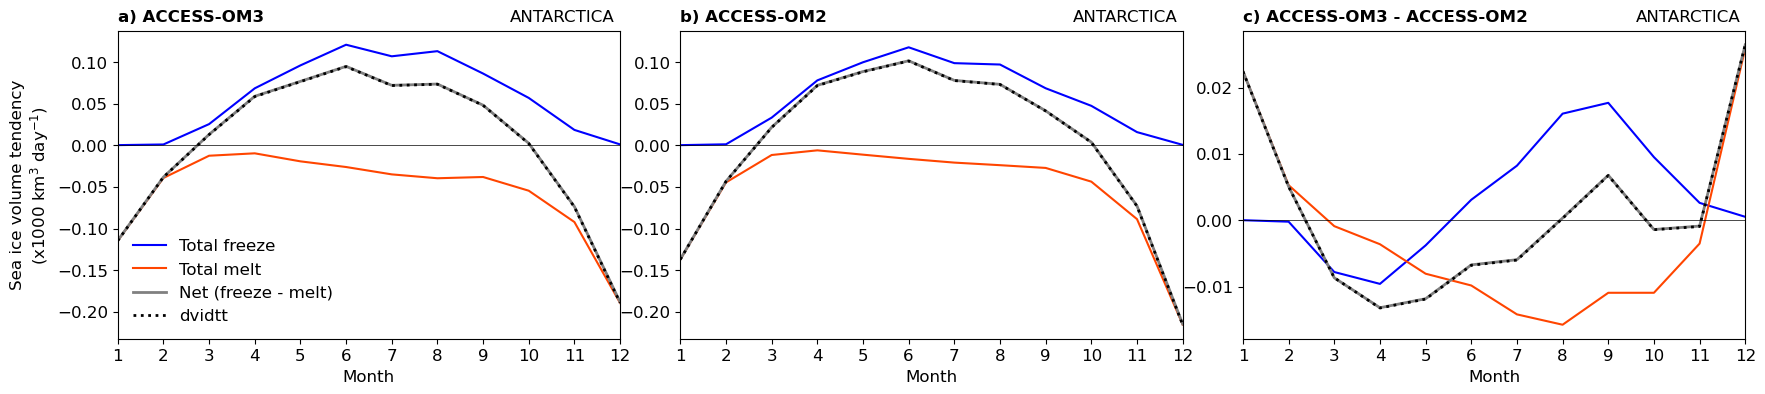

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology.md successfully.


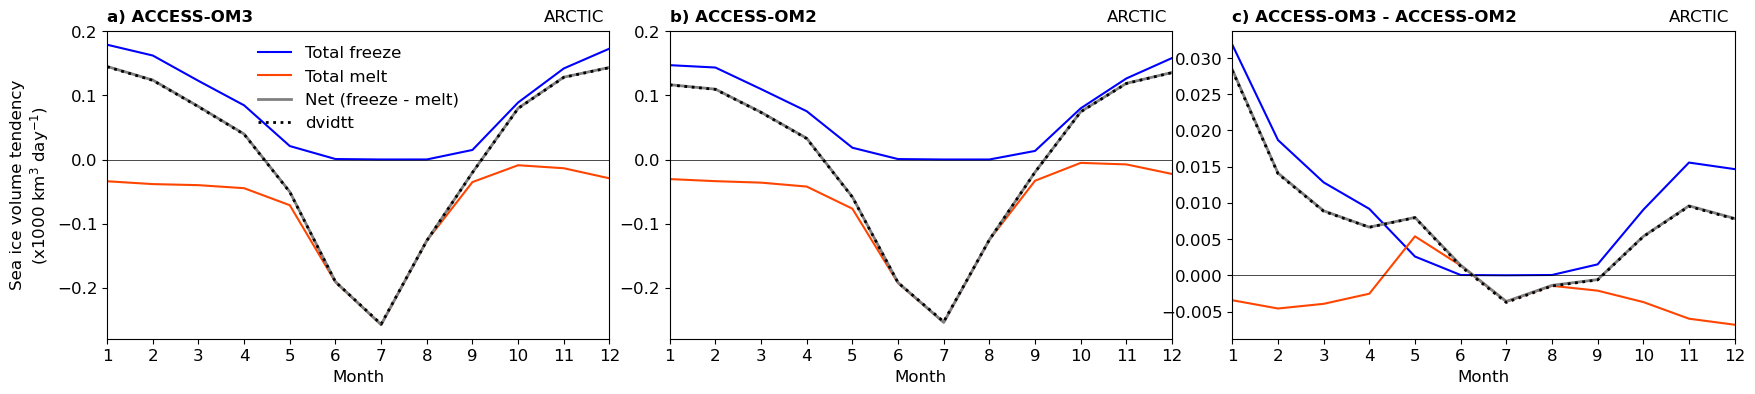

In [15]:
region_names = {'ANTARCTICA': 'Antarctic', 'ARCTIC': 'Arctic'}

def format_month_axis(ax):
    """Zero line and month ticks for a climatology panel"""
    ax.axhline(0, lw=0.5, c='k')
    ax.set_xlim([1,12])
    ax.set_xticks(np.arange(1,13,1))
    ax.set_xlabel('Month')

def plot_budget_totals(ax, clim):
    """Total freeze, total melt (as negative), net and dvidtt climatology, in 1000 km^3/day"""
    ax.plot(clim.month, clim['freeze']/1e12, c='blue', label='Total freeze')
    ax.plot(clim.month, -clim['melt']/1e12, c='orangered', label='Total melt')
    ax.plot(clim.month, (clim['freeze'] - clim['melt'])/1e12, c='grey', lw=2, label='Net (freeze - melt)')
    ax.plot(clim.month, clim['dvidtt_m']/1e12, c='k', ls=':', lw=2, label='dvidtt')

for region in ['ANTARCTICA', 'ARCTIC']:
    plt.rcParams['font.size'] = 12
    fig, axes = plt.subplots(ncols=3, figsize=(21,4), sharex=True)
    axes[1].sharey(axes[0])
    plt.subplots_adjust(wspace=0.12)

    panels = [
        ('a) ACCESS-OM3', clim_om3[region]),
        ('b) ACCESS-OM2', clim_om2[region]),
        ('c) ACCESS-OM3 - ACCESS-OM2', clim_om3[region] - clim_om2[region]),
    ]
    for ax, (title, clim) in zip(axes, panels):
        plot_budget_totals(ax, clim)
        format_month_axis(ax)
        ax.text(0.0, 1.03, title, fontsize=12, fontweight='bold', transform=ax.transAxes)
        ax.text(0.99, 1.03, region, ha='right', fontsize=12, transform=ax.transAxes)

    axes[0].set_ylabel('Sea ice volume tendency\n(x1000 km$^3$ day$^{-1}$)')
    axes[0].legend(frameon=False, fontsize=12)

    mkmd.savefig(fig, "Sea Ice Mass Budget", f"{region_names[region]} sea ice volume budget climatology comparing ACCESS-OM3 and ACCESS-OM2. [GitHub issue: Sea ice mass budget climatology](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/52)")
    plt.show()

### Check `freeze` - `melt` and `dvidtt` residuals

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology_03.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology.md successfully.


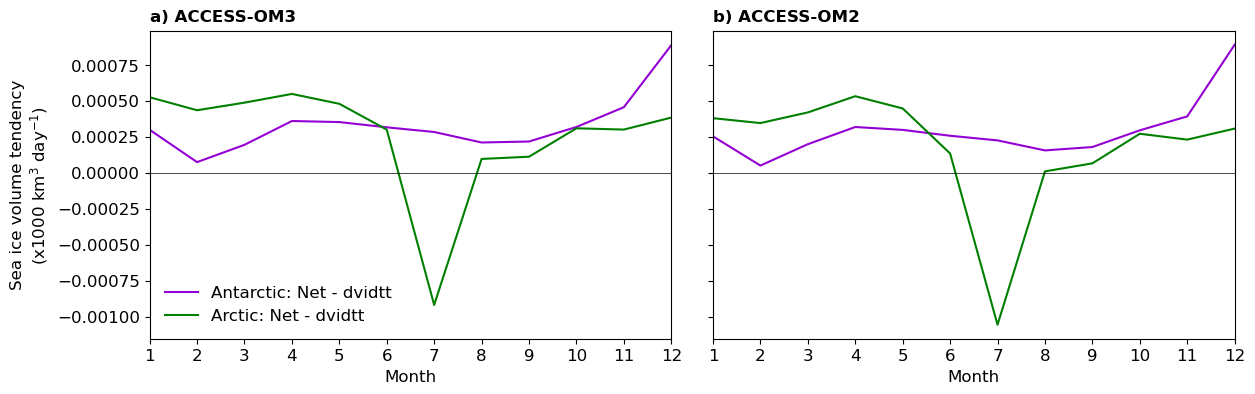

In [16]:
plt.rcParams['font.size'] = 12
fig, axes = plt.subplots(ncols=2, figsize=(14,4), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.08)

for ax, title, clim in zip(axes, ['a) ACCESS-OM3', 'b) ACCESS-OM2'], [clim_om3, clim_om2]):
    for region, c in [('ANTARCTICA', 'darkviolet'), ('ARCTIC', 'green')]:
        b = clim[region]
        ax.plot(b.month, ((b['freeze'] - b['melt']) - b['dvidtt_m'])/1e12, c=c, label=f'{region_names[region]}: Net - dvidtt')
    format_month_axis(ax)
    ax.text(0.0, 1.03, title, fontsize=12, fontweight='bold', transform=ax.transAxes)

axes[0].set_ylabel('Sea ice volume tendency\n(x1000 km$^3$ day$^{-1}$)')
axes[0].legend(frameon=False, ncols=1, fontsize=12, loc='lower left')

mkmd.savefig(fig, "Sea Ice Mass Budget", "Sea ice volume budget residual comparing ACCESS-OM3 and ACCESS-OM2. [GitHub issue: Sea ice mass budget climatology](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/52)")
plt.show()

### Annual sea ice volume budget timeseries

Annual totals of each sea ice growth and melt component over the whole of each run, comparing ACCESS-OM3 and ACCESS-OM2 on each panel, with the climatology period (`t_slice`) shaded.

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology_04.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology.md successfully.


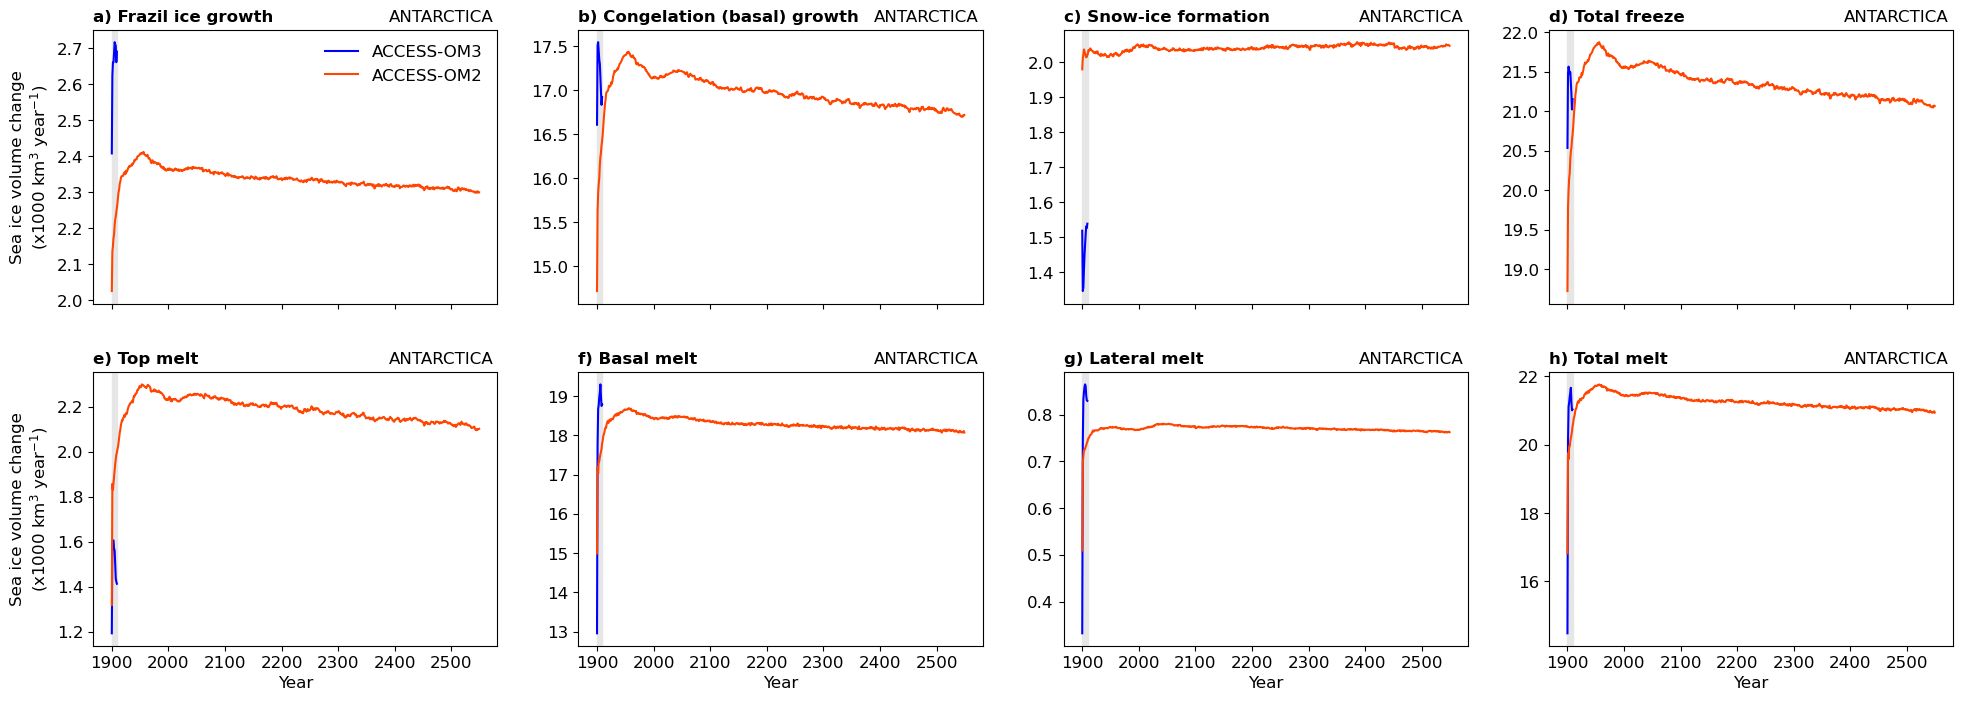

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology_05.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology.md successfully.


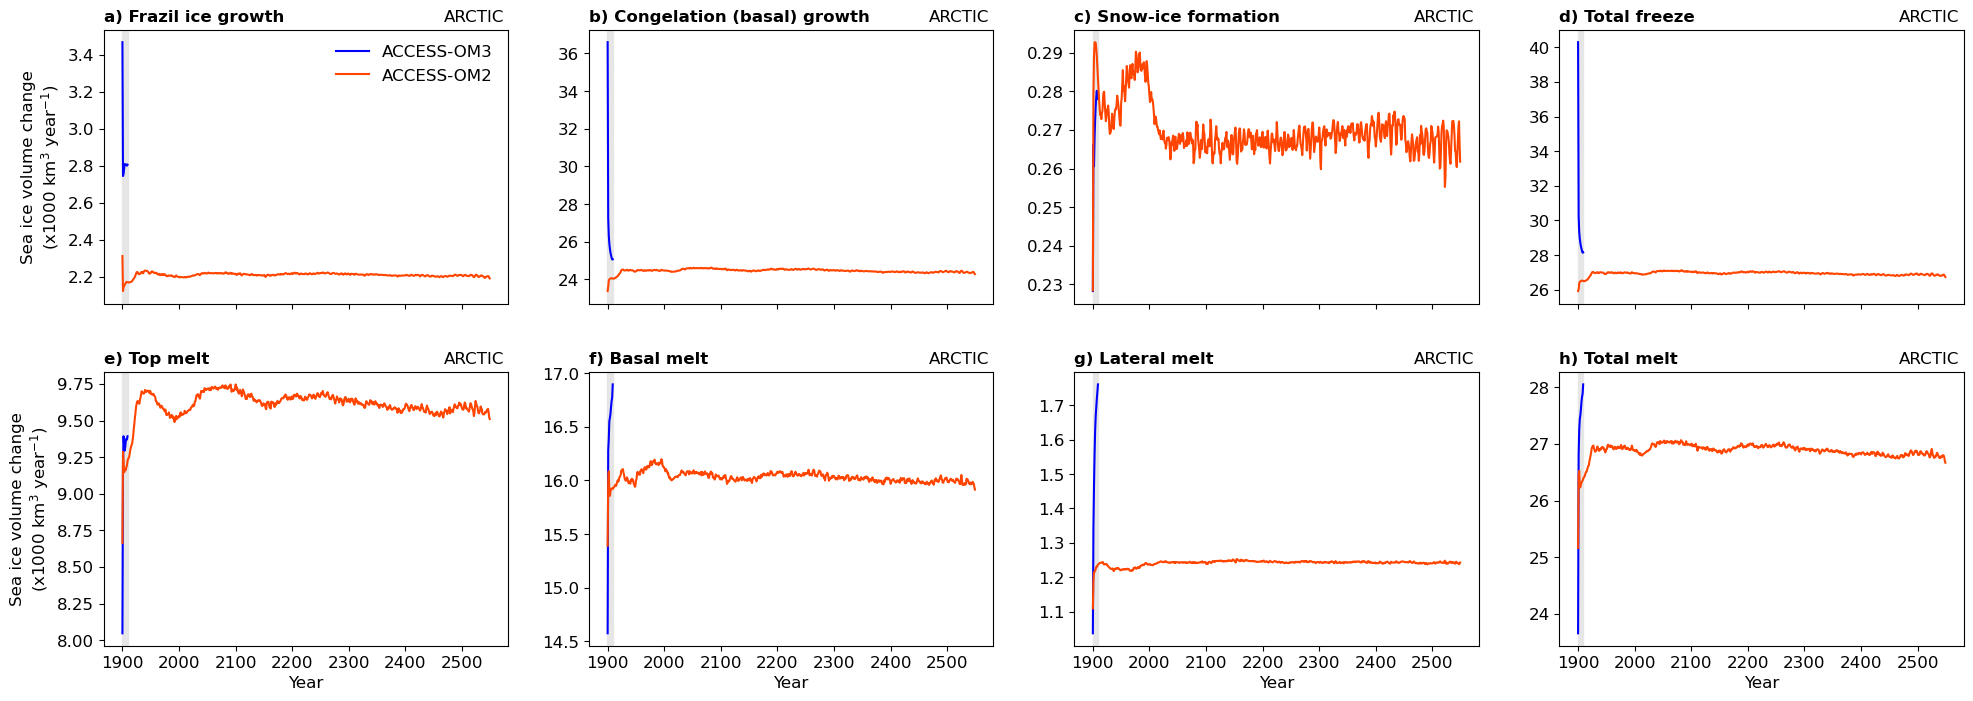

In [17]:
# Freeze components (top row) and melt components (bottom row), each with the total in the last column
budget_terms = [
    [('frazil_m', 'Frazil ice growth'), ('congel_m', 'Congelation (basal) growth'), ('snoice_m', 'Snow-ice formation'), ('freeze', 'Total freeze')],
    [('meltt_m', 'Top melt'), ('meltb_m', 'Basal melt'), ('meltl_m', 'Lateral melt'), ('melt', 'Total melt')],
]

def plot_budget_components(om3, om2, region, xdim, xlabel, ylabel):
    """
    2x4 panels of the sea ice growth and melt components and their totals, with ACCESS-OM3
    and ACCESS-OM2 on each panel. om3 and om2 are Datasets of the budget terms along xdim.
    """
    plt.rcParams['font.size'] = 12
    fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(24,8), sharex=True)
    plt.subplots_adjust(wspace=0.2, hspace=0.25)

    for row, terms in enumerate(budget_terms):
        for col, (term, name) in enumerate(terms):
            ax = axes[row, col]
            for model, data, c in [('ACCESS-OM3', om3, 'blue'), ('ACCESS-OM2', om2, 'orangered')]:
                ax.plot(data[xdim], data[term], c=c, label=model)
            ax.text(0.0, 1.03, f'{"abcdefgh"[4*row + col]}) {name}', fontsize=12, fontweight='bold', transform=ax.transAxes)
            ax.text(0.99, 1.03, region, ha='right', fontsize=12, transform=ax.transAxes)
        axes[row, 0].set_ylabel(ylabel)

    for ax in axes[1]:
        ax.set_xlabel(xlabel)
    axes[0, 0].legend(frameon=False, fontsize=12)

    return fig, axes

for region in ['ANTARCTICA', 'ARCTIC']:
    fig, axes = plot_budget_components(
        annual_om3[region]/1e3, annual_om2[region]/1e3, region,  # km^3 -> 1000 km^3
        'year', 'Year', 'Sea ice volume change\n(x1000 km$^3$ year$^{-1}$)',
    )
    for ax in axes.flat:
        ax.axvspan(int(t_slice.start) - 0.5, int(t_slice.stop) + 0.5, color='0.9', zorder=0)  # climatology period

    mkmd.savefig(fig, "Sea Ice Mass Budget", f"Annual {region_names[region]} sea ice growth and melt by component, comparing ACCESS-OM3 and ACCESS-OM2, with the climatology period shaded. [GitHub issue: Sea ice mass budget climatology](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/52)")
    plt.show()

### Sea ice volume budget climatology by component

Monthly climatology (over `t_slice`) of each sea ice growth and melt component, comparing ACCESS-OM3 and ACCESS-OM2 on each panel.

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology_06.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology.md successfully.


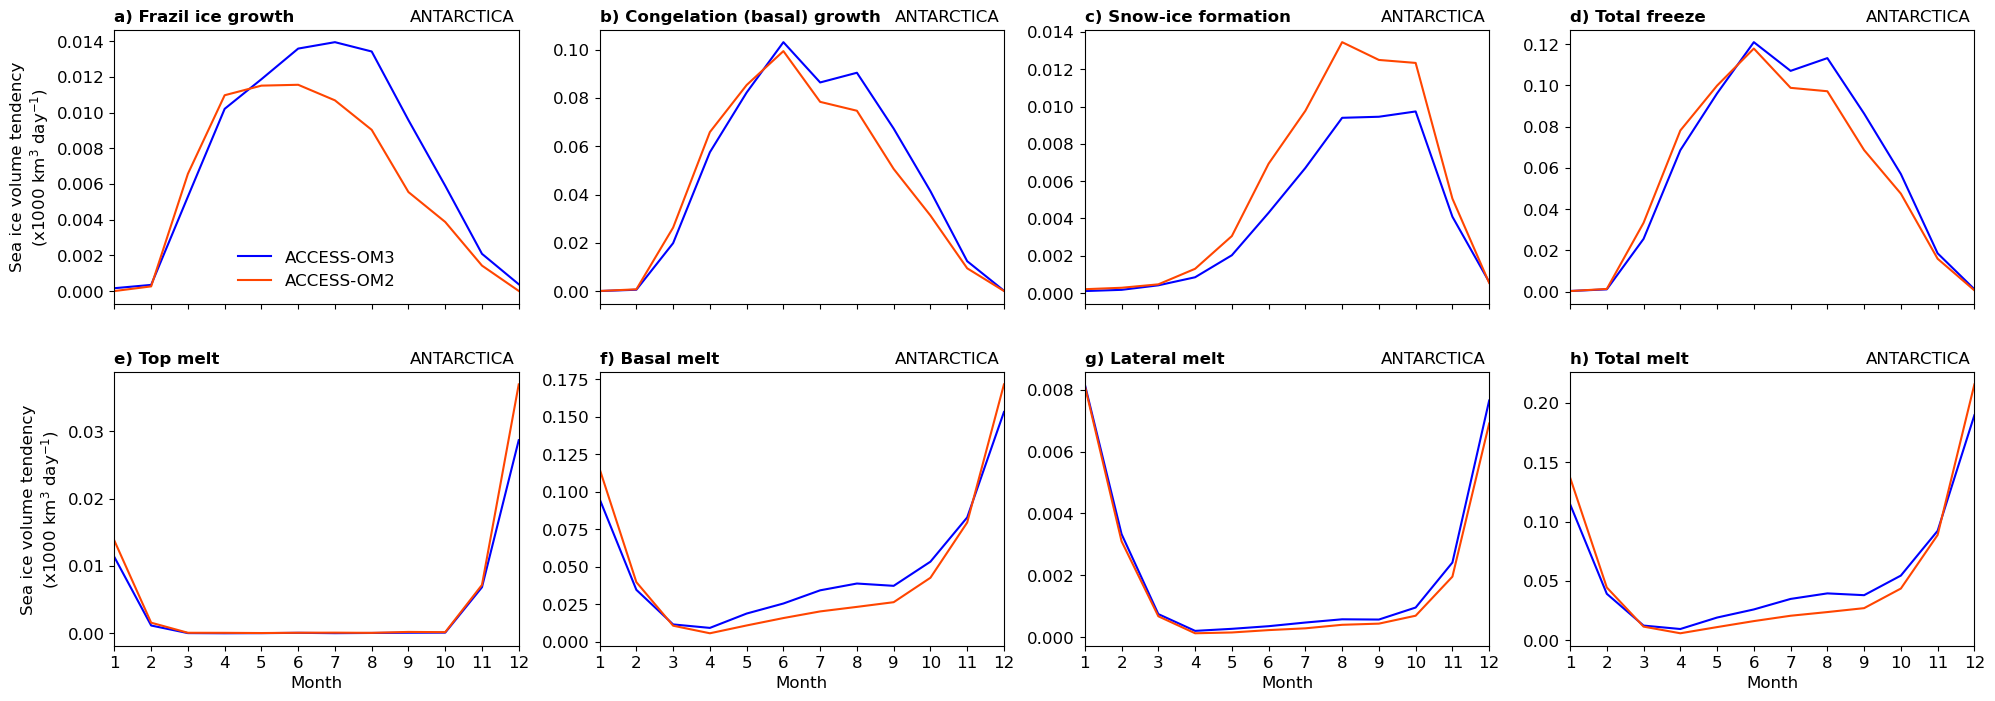

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology_07.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-1/mkmd/SeaIce_mass_budget_climatology.md successfully.


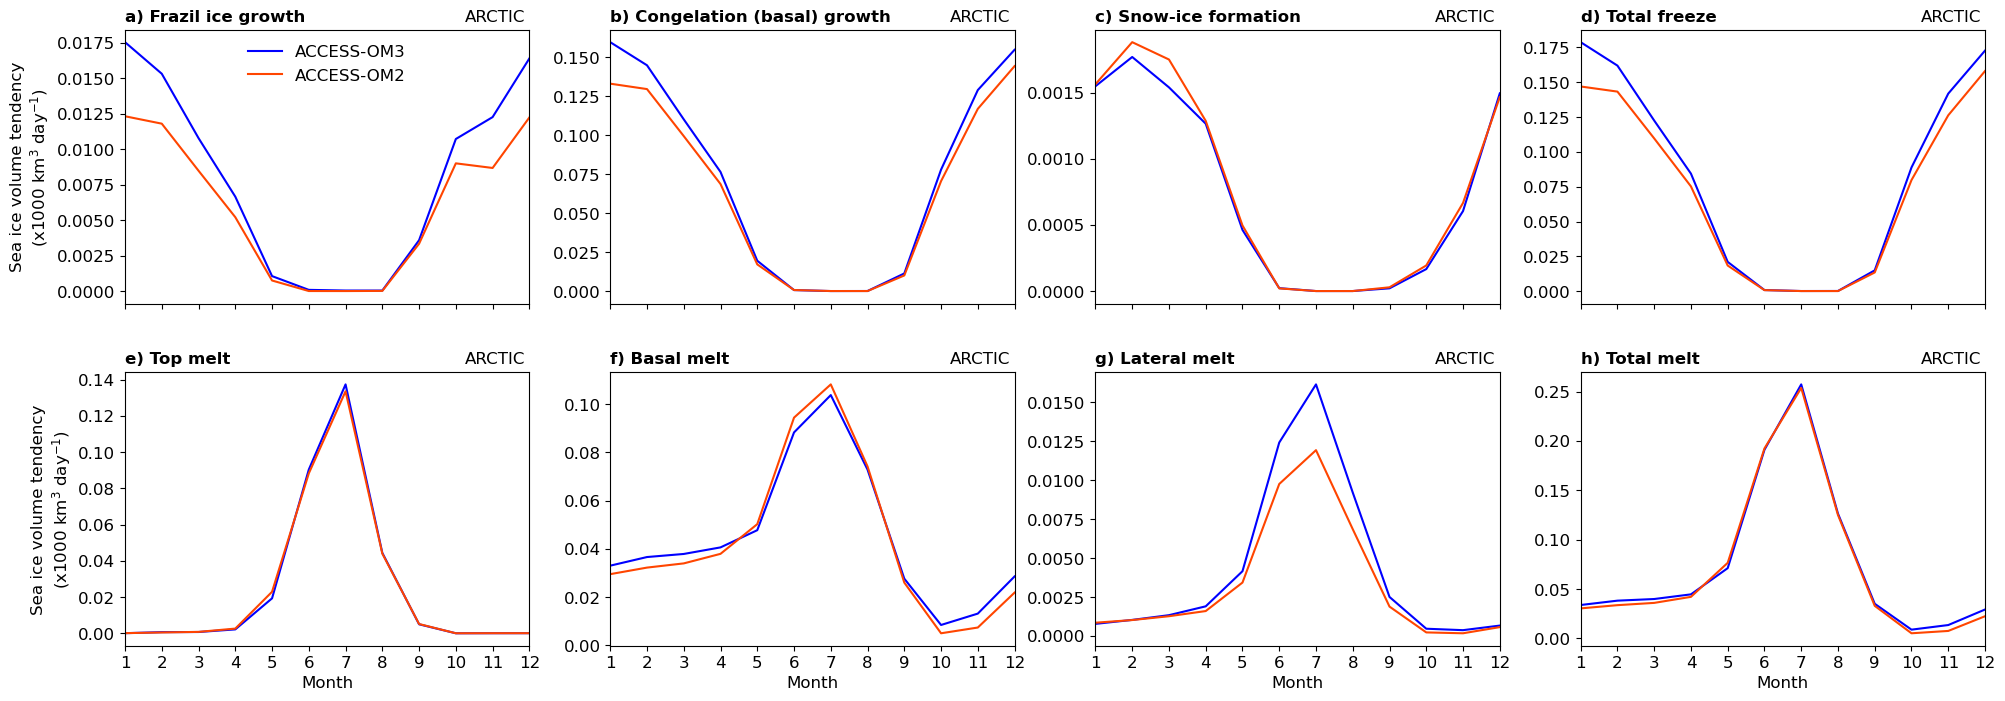

In [18]:
for region in ['ANTARCTICA', 'ARCTIC']:
    fig, axes = plot_budget_components(
        clim_om3[region]/1e12, clim_om2[region]/1e12, region,  # m^3 -> 1000 km^3
        'month', 'Month', 'Sea ice volume tendency\n(x1000 km$^3$ day$^{-1}$)',
    )
    for ax in axes.flat:
        ax.set_xlim([1,12])
        ax.set_xticks(np.arange(1,13,1))

    mkmd.savefig(fig, "Sea Ice Mass Budget", f"{region_names[region]} sea ice growth and melt climatology by component, comparing ACCESS-OM3 and ACCESS-OM2. [GitHub issue: Sea ice mass budget climatology](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/52)")
    plt.show()

In [19]:
client.close()